In [2]:
pip install implicit nltk pymorphy3 sentence-transformers seaborn tqdm matplotlib scikit-learn

Note: you may need to restart the kernel to use updated packages.


In [3]:
import os, re, json, pickle, random, warnings

from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from tqdm.auto import tqdm

from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.metrics.pairwise import cosine_similarity
from sklearn.cluster import KMeans

import nltk
from nltk.corpus import stopwords


import pymorphy3
from sentence_transformers import SentenceTransformer

warnings.filterwarnings('ignore')
sns.set_style('whitegrid')

plt.rcParams['figure.figsize'] = (12, 6)

nltk.download('stopwords')

[nltk_data] Downloading package stopwords to
[nltk_data]     C:\Users\Admin\AppData\Roaming\nltk_data...
[nltk_data]   Package stopwords is already up-to-date!


True

In [4]:
df = pd.read_csv('mproj.csv',
                 encoding='utf-8-sig', sep=',', quotechar='"', on_bad_lines='warn')

print(f"Размер: {df.shape[0]:,} строк × {df.shape[1]} колонок")
print(f"Уникальных material_id: {df['material_id'].nunique():,}")
print(f"Дубликатов: {len(df) - df['material_id'].nunique():,}")

df.head()
df.columns.tolist()

Размер: 60,000 строк × 36 колонок
Уникальных material_id: 60,000
Дубликатов: 0


['material_id',
 'material.title',
 'material.description',
 'material.content',
 'material.duration',
 'material.variants_count',
 'direction.name',
 'material.difficulty_level',
 'material.work_form',
 'subject.name',
 'grade.name',
 'module.name',
 'section.name',
 'theme.name',
 'umk.name',
 'event.name',
 'type.name',
 'format',
 'task.name',
 'material.author_purpose',
 'presentation_form',
 'material.is_method_recommendations',
 'material.approved_by_prosveshchenie',
 'material.files.archive.files_inside[].type',
 'material.task_count',
 'material.is_evaluation_criteria',
 'material.is_ovz',
 'material.type_ovz',
 'material.tso',
 'material.is_interesting_mechanic',
 'material.season',
 'slug',
 'catalog_author.name',
 'catalog_author.role',
 'URL файла материала doc\\pdf',
 'URL pptx']

In [ ]:
# duration приходит строкой вида "41 мин", вытаскиваем число
df['duration_min'] = pd.to_numeric(
    df['material.duration'].astype(str).str.extract(r'(\d+)')[0],
    errors='coerce'  
)

# grade.name бывает "7, 8", бывает "—". Парсим в set.
# frozenset, потому что потом нужен & между классами (для пересечения)
def parse_grade_set(s):
    if not isinstance(s, str) or s.strip() in ('—', '', 'nan'):
        return frozenset()
    items = set()
    for p in s.split(','):
        p = p.strip()
        if p.isdigit():
            items.add(int(p))
    return frozenset(items)

df['grade_set'] = df['grade.name'].apply(parse_grade_set)

# пустые subject/theme/direction — заменяем на "—"
# (иначе потом .str.startswith на NaN падает)
df['subject.name']   = df['subject.name'].fillna('—').astype(str).str.strip()
df['theme.name']     = df['theme.name'].fillna('—').astype(str).str.strip()
df['direction.name'] = df['direction.name'].fillna('—').astype(str).str.strip()

# мульти-списки через запятую -> кортеж
def split_multi(x):
    if pd.isna(x) or str(x).strip() in ('—', '', 'nan'):
        return tuple()
    return tuple(sorted({p.strip() for p in str(x).split(',') if p.strip()}))

df['file_types'] = df['material.files.archive.files_inside[].type'].apply(split_multi)
df['work_forms'] = df['material.work_form'].apply(split_multi)
df['tso_list']   = df['material.tso'].apply(split_multi)

# внутренний row_id — для быстрого доступа к матрицам
df = df.reset_index(drop=True)
df['row_id'] = np.arange(len(df))

df[['material_id', 'subject.name', 'direction.name', 'grade_set', 'duration_min']].head(3)

,material_id,subject.name,direction.name,grade_set,duration_min
0,588cae74-2a29-43b9-8457-02665d277b57,Музыка,lesson,frozenset({1}),41
1,000c5005-2208-47da-b009-104543498e5b,Геометрия,lesson,frozenset({10}),14
2,bb506d3f-786b-4c8d-8d77-9f6212710f07,Геометрия,lesson,frozenset({11}),7


In [6]:
## EDA: распределения и пустые

no_subject = df['subject.name'] == '—'
print("без предмета:", no_subject.sum(), f"({no_subject.mean()*100:.1f}%)")
print(df.loc[no_subject, 'direction.name'].value_counts())
# ^^ ага, всё extracurricular, логично

# быстрый обзор категориалок
for col in ['subject.name', 'direction.name', 'type.name',
            'material.difficulty_level', 'grade.name', 'theme.name']:
    print(f"\n{col} ")
    print("уник:", df[col].nunique())
    print(df[col].value_counts().head(5))

# df['theme.name'].value_counts().tail(20)

без предмета: 18122 (30.2%)
direction.name
extracurricular    18122
Name: count, dtype: int64

subject.name 
уник: 25
subject.name
—               18122
Русский язык     3659
Музыка           2772
Биология         2488
География        2415
Name: count, dtype: int64

direction.name 
уник: 2
direction.name
lesson             41878
extracurricular    18122
Name: count, dtype: int64

type.name 
уник: 15
type.name
Контрольно-оценочные материалы        5332
Дидактический материал                5320
Игровые задания                       5298
Сценарий урока                        5252
Лабораторные и практические работы    5200
Name: count, dtype: int64

material.difficulty_level 
уник: 3
material.difficulty_level
базовый        33966
—              18122
углублённый     7912
Name: count, dtype: int64

grade.name 
уник: 561
grade.name
8     5851
9     5574
7     5415
11    5315
10    5255
Name: count, dtype: int64

theme.name 
уник: 12067
theme.name
Школьный театр          1072
Осень в стихах

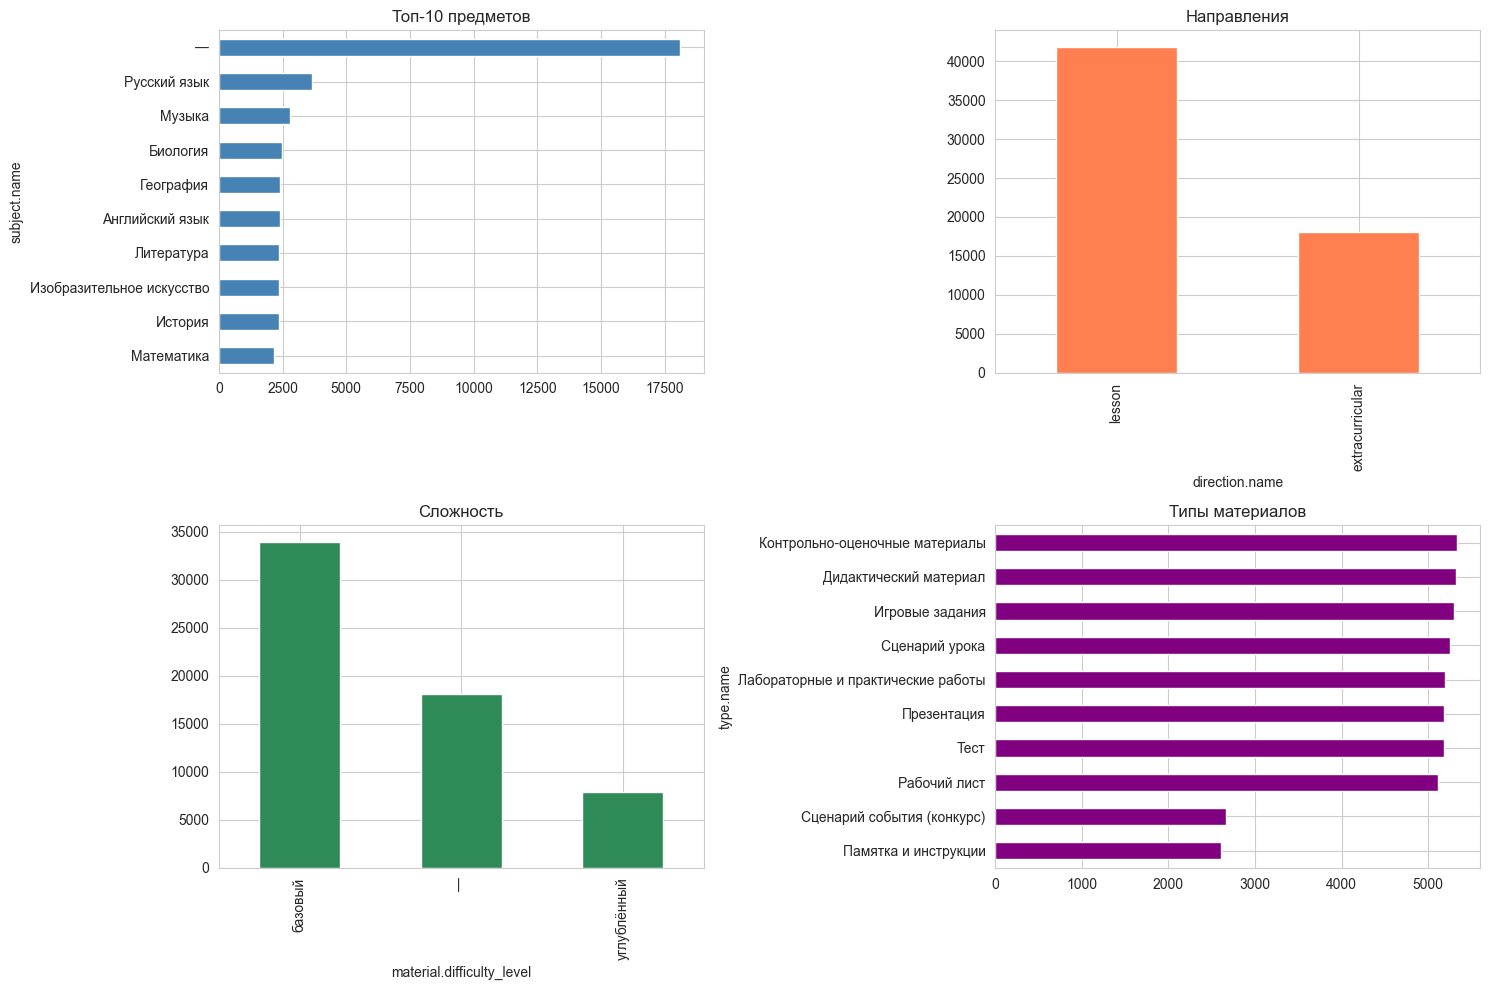

In [7]:
fig, axes = plt.subplots(2, 2, figsize=(15, 10))

df['subject.name'].value_counts().head(10).plot(kind='barh', ax=axes[0, 0], color='steelblue')
axes[0, 0].set_title('Топ-10 предметов')
axes[0, 0].invert_yaxis()

df['direction.name'].value_counts().plot(kind='bar', ax=axes[0, 1], color='coral')
axes[0, 1].set_title('Направления')

df['material.difficulty_level'].value_counts().plot(kind='bar', ax=axes[1, 0], color='seagreen')
axes[1, 0].set_title('Сложность')

df['type.name'].value_counts().head(10).plot(kind='barh', ax=axes[1, 1], color='purple')
axes[1, 1].set_title('Типы материалов')
axes[1, 1].invert_yaxis()

plt.tight_layout()
plt.show()

In [8]:
# собираем весь текст в одну кучу
def build_text(row):
    parts = []

    # title + description + content
    for col in ['material.title', 'material.description', 'material.content']:
        v = row.get(col)
        if isinstance(v, str) and v.strip() and v.strip() != '—':
            parts.append(v)

    # тема/раздел/модуль/предмет — самые информативные
    for col in ['theme.name', 'section.name', 'module.name', 'subject.name']:
        v = row.get(col)
        if isinstance(v, str) and v.strip() and v.strip() != '—':
            parts.append(v)

    # тип/сложность/формат — тоже полезно
    for col in ['type.name', 'material.difficulty_level',
                'task.name', 'presentation_form', 'material.author_purpose',
                'format', 'umk.name']:
        v = row.get(col)
        if isinstance(v, str) and v.strip() and v.strip() != '—':
            parts.append(v)

    # мульти-списки (кортежи)
    parts.extend(row.get('file_types', ()))
    parts.extend(row.get('work_forms', ()))

    return ' '.join(parts).strip()

df['full_text'] = df.apply(build_text, axis=1)

print(f"Средняя длина: {df['full_text'].str.len().mean():.0f}")
print(f"Пустых: {(df['full_text'].str.len() == 0).sum()}")
print("\nПример:")
print(df['full_text'].iloc[0][:400])

Средняя длина: 401
Пустых: 0

Пример:
Сценарий урока «Музыка стран дальнего зарубежья» Пошаговый сценарий урока по теме: Музыка стран дальнего зарубежья Введение, практика, рефлексия Музыка стран дальнего зарубежья: музыка Испании и Латинской Америки; фламенко; искусство игры на гитаре, кастаньеты, латиноамериканские ударные инструменты; танцевальные жанры Музыка стран дальнего зарубежья: музыка народов Европы; танцевальный и песенный


In [9]:
# Лемматизация

morph = pymorphy3.MorphAnalyzer()

# стандартные русские стоп-слова + наши доменные (материал, урок, класс...)
RU_STOP = set(stopwords.words('russian'))
RU_STOP |= {
    'материал', 'занятие', 'урок', 'класс', 'работа', 'задание',
    'использование', 'помощь', 'помощью', 'также', 'который',
    'может', 'подходит', 'включает', 'содержит',
    'тема', 'тип', 'уроки', 'занятия', 'классы',
}
# может, ещё 'школа', 'ученик' убрать? проверить на топ-словах

punct_re = re.compile(r'[^а-яёa-z0-9\s]', re.IGNORECASE)

def preprocess(text):
    if not isinstance(text, str) or not text:
        return ''
    text = text.lower()
    text = punct_re.sub(' ', text)
    tokens = [t for t in text.split() if len(t) > 2 and t not in RU_STOP]

    tokens = [morph.parse(t)[0].normal_form for t in tokens]
    return ' '.join(tokens)

tqdm.pandas(desc='Lemmatize')
df['clean_text'] = df['full_text'].progress_apply(preprocess)
print(f"Непустых: {(df['clean_text'].str.len() > 0).sum()}/{len(df)}")

Lemmatize:   0%|          | 0/60000 [00:00<?, ?it/s]

Непустых: 60000/60000


In [10]:
tfidf = TfidfVectorizer(
    max_features=15000,
    min_df=2,
    max_df=0.95,
    ngram_range=(1, 2),
    sublinear_tf=True,
)
tfidf_matrix = tfidf.fit_transform(df['clean_text'])

print(f"TF-IDF: {tfidf_matrix.shape}")
print(f"nnz: {tfidf_matrix.nnz:,}")
print(f"плотность: {tfidf_matrix.nnz / (tfidf_matrix.shape[0]*tfidf_matrix.shape[1]) * 100:.3f}%")

# топ-слова — смотрим, что вообще выучилось
feat = tfidf.get_feature_names_out()
mean_tfidf = np.asarray(tfidf_matrix.mean(axis=0)).flatten()
for idx in np.argsort(-mean_tfidf)[:15]:
    print(f"  {feat[idx]}: {mean_tfidf[idx]:.4f}")
# 'сценарий' и 'печать' в топе — норм? может, они слишком частые?

TF-IDF: (60000, 15000)
nnz: 3,086,006
плотность: 0.343%
  сценарий: 0.0248
  печать: 0.0227
  задание: 0.0209
  цифровой: 0.0191
  практический: 0.0186
  групповой: 0.0180
  парный: 0.0179
  навык: 0.0170
  развить: 0.0169
  базовый: 0.0167
  инструкция: 0.0166
  проект: 0.0155
  печать цифровой: 0.0151
  конкурс: 0.0148
  знание: 0.0148


In [11]:
TOP_K = 50
BATCH = 512
N = df.shape[0]

tfidf_idx   = np.zeros((N, TOP_K), dtype=np.int32)
tfidf_score = np.zeros((N, TOP_K), dtype=np.float32)

for start in range(0, N, BATCH):
    end = min(start + BATCH, N)
    block = cosine_similarity(tfidf_matrix[start:end], tfidf_matrix)

    # себя из выдачи убираем
    for li, gi in enumerate(range(start, end)):
        block[li, gi] = 0.0

    # argpartition быстрее полного argsort
    part = np.argpartition(-block, TOP_K, axis=1)[:, :TOP_K]
    for li in range(end - start):
        ids = part[li]
        order = np.argsort(-block[li, ids])
        tfidf_idx[start + li]   = ids[order]
        tfidf_score[start + li] = block[li, ids[order]]
    del block   

print(f"TF-IDF top-1 mean: {tfidf_score[:, 0].mean():.4f}")

TF-IDF top-1 mean: 0.8526


In [12]:
# Semantic эмбеддинги

# rubert-tiny2 — маленькая и быстрая, для baseline хватит
# (пробовала rubert-base — 3x медленнее, качество не сильно лучше на этой задаче)
MODEL_NAME = 'cointegrated/rubert-tiny2'
st = SentenceTransformer(MODEL_NAME)

emb = st.encode(
    df['clean_text'].tolist(),
    batch_size=32,              
    show_progress_bar=True,
    convert_to_numpy=True,
    normalize_embeddings=True,  
)
print(f"Embeddings: {emb.shape}")

# на всякий случай проверим, что нормы ~1
print("норма[0]:", np.linalg.norm(emb[0]))

Loading weights:   0%|          | 0/55 [00:00<?, ?it/s]

[transformers] BertModel LOAD REPORT from: cointegrated/rubert-tiny2
Key                                        | Status     |  | 
-------------------------------------------+------------+--+-
cls.seq_relationship.weight                | UNEXPECTED |  | 
cls.predictions.transform.LayerNorm.weight | UNEXPECTED |  | 
cls.seq_relationship.bias                  | UNEXPECTED |  | 
cls.predictions.transform.LayerNorm.bias   | UNEXPECTED |  | 
cls.predictions.transform.dense.bias       | UNEXPECTED |  | 
cls.predictions.bias                       | UNEXPECTED |  | 
cls.predictions.transform.dense.weight     | UNEXPECTED |  | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.


Batches:   0%|          | 0/1875 [00:00<?, ?it/s]

Embeddings: (60000, 312)
норма[0]: 1.0


In [13]:
# Semantic top-K батчами

sem_idx   = np.zeros((N, TOP_K), dtype=np.int32)
sem_score = np.zeros((N, TOP_K), dtype=np.float32)

for start in range(0, N, BATCH):
    end = min(start + BATCH, N)
    # эмбеддинги уже нормированы — просто dot
    block = emb[start:end] @ emb.T
    for li, gi in enumerate(range(start, end)):
        block[li, gi] = 0.0

    part = np.argpartition(-block, TOP_K, axis=1)[:, :TOP_K]
    for li in range(end - start):
        ids = part[li]
        order = np.argsort(-block[li, ids])
        sem_idx[start + li]   = ids[order]
        sem_score[start + li] = block[li, ids[order]]
    del block

print(f"Semantic top-1 mean: {sem_score[:, 0].mean():.4f}")

Semantic top-1 mean: 0.9737


In [14]:
# сэмпл 2000 — чтобы матрицу 60k x 60k не строить 
SAMPLE_N = 2000
# локальный rng — чтобы графики воспроизводились, но глобальный seed не трогаем
rng = np.random.default_rng(123)
sample_idx = rng.choice(len(df), size=min(SAMPLE_N, len(df)), replace=False)

print(f"Сэмпл: {len(sample_idx)} материалов из {len(df)}")

# TF-IDF (разреженная -> плотная на сэмпле)
tfidf_similarity = (
    tfidf_matrix[sample_idx] @ tfidf_matrix[sample_idx].T
).toarray()

# Semantic (плотная, уже нормированная)
semantic_similarity = emb[sample_idx] @ emb[sample_idx].T

print(f"tfidf_similarity:    {tfidf_similarity.shape}")
print(f"semantic_similarity: {semantic_similarity.shape}")

Сэмпл: 2000 материалов из 60000
tfidf_similarity:    (2000, 2000)
semantic_similarity: (2000, 2000)


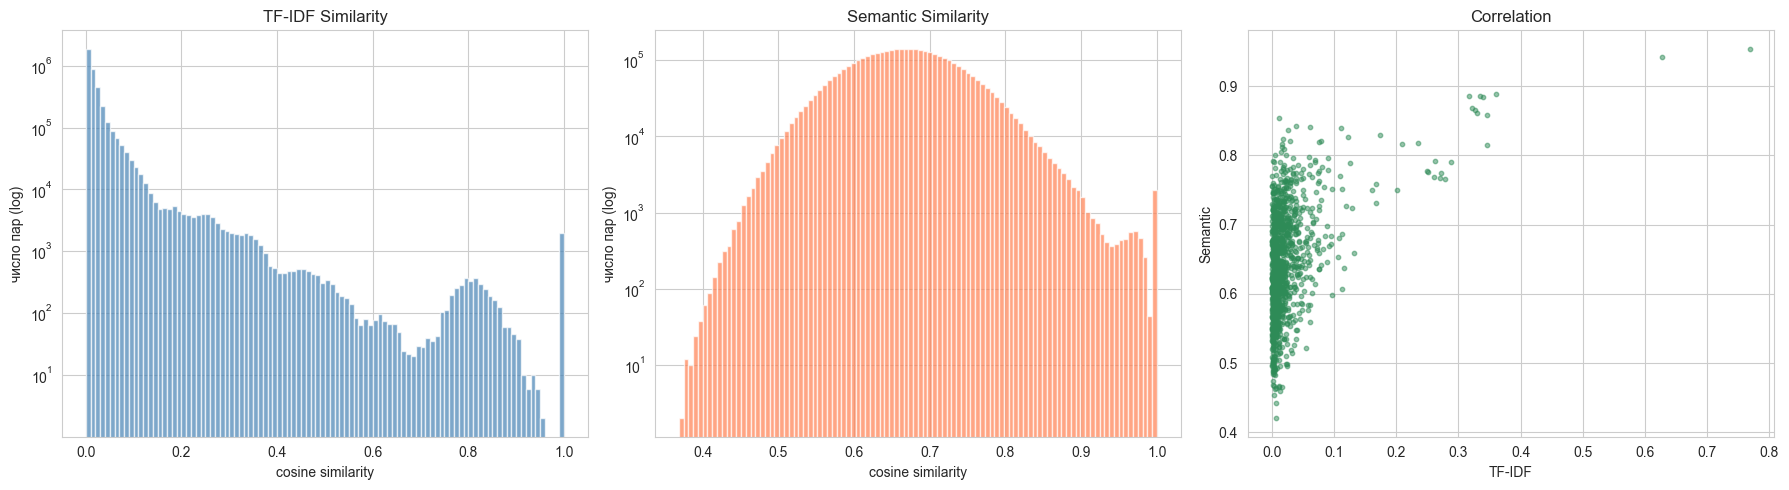

Корреляция: 0.4391

Пересечение top-K:
  @ 5: 0.518
  @10: 0.521
  @20: 0.513
  @50: 0.536


In [15]:
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

# TF-IDF — распределение сходств
axes[0].hist(tfidf_similarity.flatten(), bins=100, color='steelblue', alpha=0.7)
axes[0].set_title('TF-IDF Similarity')
axes[0].set_xlabel('cosine similarity')
axes[0].set_ylabel('число пар (log)')
axes[0].set_yscale('log')

# Semantic — тоже
axes[1].hist(semantic_similarity.flatten(), bins=100, color='coral', alpha=0.7)
axes[1].set_title('Semantic Similarity')
axes[1].set_xlabel('cosine similarity')
axes[1].set_ylabel('число пар (log)')
axes[1].set_yscale('log')

# корреляция — на 50x50 парах, чтобы не пересчитывать 2000x2000
n = len(sample_idx)
pairs_i = rng.choice(n, size=min(50, n), replace=False)
pairs = []
for i in pairs_i:
    for j in pairs_i:
        if i < j:
            pairs.append((tfidf_similarity[i, j], semantic_similarity[i, j]))
pairs = np.array(pairs)

if len(pairs) > 0:
    axes[2].scatter(pairs[:, 0], pairs[:, 1], alpha=0.5, s=10, color='seagreen')
axes[2].set_xlabel('TF-IDF')
axes[2].set_ylabel('Semantic')
axes[2].set_title('Correlation')

plt.tight_layout()
plt.show()

if len(pairs) > 0:
    corr = np.corrcoef(pairs[:, 0], pairs[:, 1])[0, 1]
    print(f"Корреляция: {corr:.4f}")
    # ~0.44 — слабая, значит модели ищут разное

# пересечение top-K
def overlap_at_k(idx_a, idx_b, k=10):
    ov = [len(set(idx_a[i, :k]) & set(idx_b[i, :k])) / k for i in range(len(idx_a))]
    return np.mean(ov)

print("\nПересечение top-K:")
for k in [5, 10, 20, 50]:
    ov = overlap_at_k(tfidf_idx, sem_idx, k=k)
    print(f"  @{k:2d}: {ov:.3f}")
# ~0.5 — половина общая, половина разная

In [16]:
# Hybrid подбор α

def make_hybrid(tfidf_i, tfidf_s, sem_i, sem_s, alpha, K=TOP_K):
    N = tfidf_i.shape[0]
    hidx = np.zeros((N, K), dtype=np.int32)
    hscr = np.zeros((N, K), dtype=np.float32)

    for i in tqdm(range(N), desc=f'Hybrid a={alpha:.1f}'):
        td = dict(zip(tfidf_i[i], tfidf_s[i]))
        sd = dict(zip(sem_i[i],   sem_s[i]))

        cand = [c for c in (set(td) | set(sd)) if c != i]
        if not cand:
            continue
        cand = np.asarray(cand, dtype=np.int32)
        t = np.array([td.get(c, 0.0) for c in cand], dtype=np.float32)
        s = np.array([sd.get(c, 0.0) for c in cand], dtype=np.float32)

        hs = alpha * t + (1 - alpha) * s
        order = np.argsort(-hs)[:K]
        hidx[i] = cand[order]
        hscr[i] = hs[order]
    return hidx, hscr

In [17]:
# Ground truth (по двум пространствам отдельно)


# признаки для релевантности

REL_CODES_COLS = [
    'theme.name', 'section.name', 'module.name',
    'type.name', 'material.difficulty_level',
]
rel_codes = {c: pd.factorize(df[c].astype(str))[0] for c in REL_CODES_COLS}

# work_forms — мульти, кодируем битовыми масками
all_wf = sorted({w for ws in df['work_forms'] for w in ws})
wf_to_idx = {w: i for i, w in enumerate(all_wf)}
wf_mask = np.zeros((len(df), len(all_wf)), dtype=bool)
for i, ws in enumerate(df['work_forms']):
    for w in ws:
        wf_mask[i, wf_to_idx[w]] = True

# file_types — аналогично
all_ft = sorted({f for fs in df['file_types'] for f in fs})
ft_to_idx = {f: i for i, f in enumerate(all_ft)}
ft_mask = np.zeros((len(df), len(all_ft)), dtype=bool)
for i, fs in enumerate(df['file_types']):
    for f in fs:
        ft_mask[i, ft_to_idx[f]] = True

WEIGHTS = {
    'same_theme':        3.0,
    'same_section':      2.0,
    'same_module':       1.0,
    'same_type':         1.5,
    'same_difficulty':   1.0,
    'grade_overlap':     2.0,
    'work_form_overlap': 0.5,
    'file_type_overlap': 0.3,
}

def build_group_key(row):
    direc = row['direction.name']
    subj  = row['subject.name']
    theme = row['theme.name']

    # внеурочка без предмета -> группируем по теме
    if direc == 'extracurricular' and subj == '—':
        if theme == '—' or not theme:
            return 'EXTRA::_other'
        return 'EXTRA::' + theme
    # обычные предметные
    if subj != '—':
        return 'SUBJ::' + subj
    return 'OTHER::' + (theme if theme != '—' else '_other')

df['group_key'] = df.apply(build_group_key, axis=1)
group_codes = pd.factorize(df['group_key'])[0]
group_members = {}
for i, c in enumerate(group_codes):
    group_members.setdefault(c, []).append(i)
group_members = {k: np.asarray(v) for k, v in group_members.items()}

print(f"Всего групп: {len(group_members)}")
sizes = sorted((len(v) for v in group_members.values()), reverse=True)
print(f"Топ-5 размеров: {sizes[:5]}")
print(f"Групп размера 1: {sum(1 for x in sizes if x == 1)}")
print(f"Групп размера <5: {sum(1 for x in sizes if x < 5)}")

def group_by_prefix(prefix):
    return [k for k, v in group_members.items() if df['group_key'].iloc[v[0]].startswith(prefix)]
print(f"SUBJ групп: {len(group_by_prefix('SUBJ::'))}")
print(f"EXTRA групп: {len(group_by_prefix('EXTRA::'))}")
print(f"OTHER групп: {len(group_by_prefix('OTHER::'))}")

grade_sets = df['grade_set'].tolist()

def relevance_scores(i, cand):
    scores = np.zeros(len(cand), dtype=np.float32)
    scores += (rel_codes['theme.name'][cand] == rel_codes['theme.name'][i]) * WEIGHTS['same_theme']
    scores += (rel_codes['section.name'][cand] == rel_codes['section.name'][i]) * WEIGHTS['same_section']
    scores += (rel_codes['module.name'][cand] == rel_codes['module.name'][i]) * WEIGHTS['same_module']
    scores += (rel_codes['type.name'][cand] == rel_codes['type.name'][i]) * WEIGHTS['same_type']
    scores += (rel_codes['material.difficulty_level'][cand] == rel_codes['material.difficulty_level'][i]) * WEIGHTS['same_difficulty']

    gi = grade_sets[i]
    if gi:
        for pos, j in enumerate(cand):
            if grade_sets[j] & gi:
                scores[pos] += WEIGHTS['grade_overlap']

    inter_wf = wf_mask[cand] & wf_mask[i]
    scores += inter_wf.any(axis=1).astype(np.float32) * WEIGHTS['work_form_overlap']

    inter_ft = ft_mask[cand] & ft_mask[i]
    scores += inter_ft.any(axis=1).astype(np.float32) * WEIGHTS['file_type_overlap']
    return scores

def build_ground_truth(threshold, top_k=20):
    gt = {}
    for i in tqdm(range(len(df)), desc=f'GT thr={threshold}'):
        members = group_members[group_codes[i]]
        cand = members[members != i]
        if len(cand) == 0:
            gt[i] = []
            continue
        scores = relevance_scores(i, cand)
        mask = scores >= threshold
        c, s = cand[mask], scores[mask]
        if len(c) == 0:
            gt[i] = []
            continue
        if len(c) > top_k:
            c = c[np.argsort(-s)[:top_k]]
        gt[i] = [int(x) for x in c]
    return gt


gt_easy   = build_ground_truth(threshold=3.0)
gt_medium = build_ground_truth(threshold=5.0)
gt_hard   = build_ground_truth(threshold=7.0)

for name, gt in [('easy', gt_easy), ('medium', gt_medium), ('hard', gt_hard)]:
    with_rel = sum(1 for v in gt.values() if v)
    avg = np.mean([len(v) for v in gt.values()])
    print(f"{name}: с релевантными={with_rel}/{len(gt)}, avg={avg:.1f}")

Всего групп: 42
Топ-5 размеров: [3659, 2772, 2488, 2415, 2407]
Групп размера 1: 0
Групп размера <5: 0
SUBJ групп: 24
EXTRA групп: 18
OTHER групп: 0


GT thr=3.0:   0%|          | 0/60000 [00:00<?, ?it/s]

GT thr=5.0:   0%|          | 0/60000 [00:00<?, ?it/s]

GT thr=7.0:   0%|          | 0/60000 [00:00<?, ?it/s]

easy: с релевантными=60000/60000, avg=20.0
medium: с релевантными=60000/60000, avg=19.8
hard: с релевантными=59304/60000, avg=11.6


In [18]:
def precision_at_k(recs, rel, k):
    if k <= 0:
        return 0.0
    return len(set(recs[:k]) & set(rel)) / k

def recall_at_k(recs, rel, k):
    if not rel:
        return 0.0
    return len(set(recs[:k]) & set(rel)) / len(rel)

def ndcg_at_k(recs, rel, k):
    rel_set = set(rel)
    dcg = sum(1.0 / np.log2(r + 1) for r, it in enumerate(recs[:k], 1) if it in rel_set)
    idcg = sum(1.0 / np.log2(r + 1) for r in range(1, min(len(rel), k) + 1))
    return dcg / idcg if idcg > 0 else 0.0

def evaluate(top_idx, gt, k=10, subset_mask=None):
    prec, rec, ndcg = [], [], []
    for i, rel in gt.items():
        if not rel:
            continue
        if subset_mask is not None and not subset_mask[i]:
            continue
        recs = [int(x) for x in top_idx[i][:k + 1] if x != i][:k]
        prec.append(precision_at_k(recs, rel, k))
        rec.append(recall_at_k(recs, rel, k))
        ndcg.append(ndcg_at_k(recs, rel, k))
    n = len(prec)
    return {
        f'P@{k}':    float(np.mean(prec)) if n else 0.0,
        f'R@{k}':    float(np.mean(rec))  if n else 0.0,
        f'NDCG@{k}': float(np.mean(ndcg)) if n else 0.0,
        'N':         n,
    }

In [19]:
is_extra = df['group_key'].str.startswith('EXTRA::').values
is_subj  = df['group_key'].str.startswith('SUBJ::').values
is_other = df['group_key'].str.startswith('OTHER::').values

subsets = [
    ('all',             None),
    ('subjects',        is_subj),
    ('extracurricular', is_extra),
    ('other',           is_other),
]

rows = []
for mode, gt in [('easy', gt_easy), ('medium', gt_medium), ('hard', gt_hard)]:
    for sname, mask in subsets:
        for mname, top_idx in [('TF-IDF', tfidf_idx), ('Semantic', sem_idx)]:
            m = evaluate(top_idx, gt, k=10, subset_mask=mask)
            rows.append({'Mode': mode, 'Subset': sname, 'Model': mname, **m})

res_df = pd.DataFrame(rows)
print(res_df.to_string(index=False))

  Mode          Subset    Model     P@10     R@10  NDCG@10     N
  easy             all   TF-IDF 0.543502 0.271751 0.584445 60000
  easy             all Semantic 0.455847 0.227923 0.503945 60000
  easy        subjects   TF-IDF 0.709179 0.354590 0.765839 41878
  easy        subjects Semantic 0.566008 0.283004 0.632433 41878
  easy extracurricular   TF-IDF 0.160639 0.080320 0.165263 18122
  easy extracurricular Semantic 0.201275 0.100637 0.207024 18122
  easy           other   TF-IDF 0.000000 0.000000 0.000000     0
  easy           other Semantic 0.000000 0.000000 0.000000     0
medium             all   TF-IDF 0.543092 0.275075 0.584351 60000
medium             all Semantic 0.455340 0.230045 0.503667 60000
medium        subjects   TF-IDF 0.708592 0.359351 0.765704 41878
medium        subjects Semantic 0.565282 0.286044 0.632034 41878
medium extracurricular   TF-IDF 0.160639 0.080320 0.165263 18122
medium extracurricular Semantic 0.201275 0.100637 0.207024 18122
medium           other   

Hybrid a=0.0:   0%|          | 0/60000 [00:00<?, ?it/s]

Hybrid a=0.1:   0%|          | 0/60000 [00:00<?, ?it/s]

Hybrid a=0.2:   0%|          | 0/60000 [00:00<?, ?it/s]

Hybrid a=0.3:   0%|          | 0/60000 [00:00<?, ?it/s]

Hybrid a=0.4:   0%|          | 0/60000 [00:00<?, ?it/s]

...

Hybrid a=0.7:   0%|          | 0/60000 [00:00<?, ?it/s]

Hybrid a=0.8:   0%|          | 0/60000 [00:00<?, ?it/s]

Hybrid a=0.9:   0%|          | 0/60000 [00:00<?, ?it/s]

Hybrid a=1.0:   0%|          | 0/60000 [00:00<?, ?it/s]

 alpha     P@10     R@10  NDCG@10     N
   0.0 0.455340 0.230045 0.503671 60000
   0.1 0.511918 0.258834 0.557831 60000
   0.2 0.520297 0.263138 0.566525 60000
   0.3 0.522967 0.264512 0.569207 60000
   0.4 0.523772 0.264938 0.570069 60000
   0.5 0.524043 0.265082 0.570378 60000
   0.6 0.524748 0.265438 0.570857 60000
   0.7 0.527360 0.266799 0.572656 60000
   0.8 0.530900 0.268644 0.575247 60000
   0.9 0.538980 0.272847 0.581454 60000
   1.0 0.543092 0.275075 0.584354 60000

Best a = 1.0


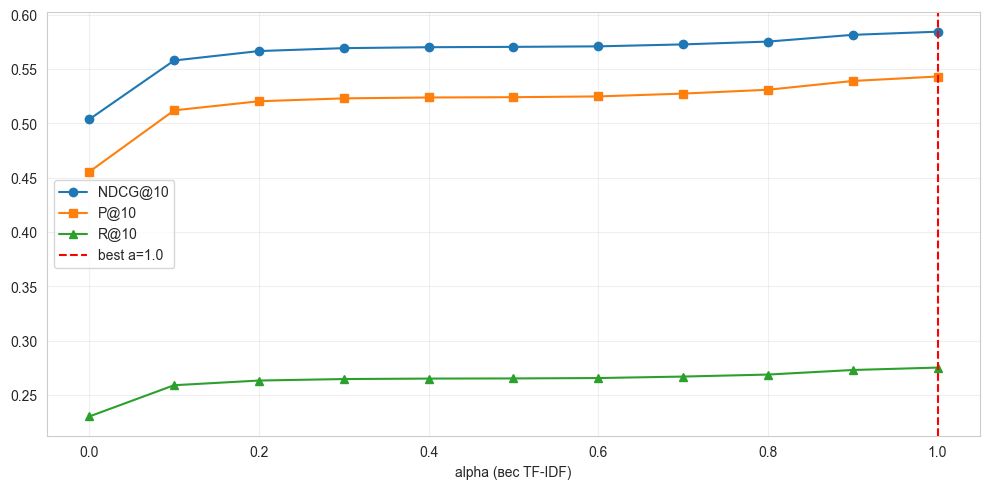

In [20]:
# подбираем alpha: 0 = только semantic, 1 = только tf-idf
# шаг 0.1 — потом можно сузить, если найдём оптимум на краю
alphas = np.round(np.arange(0.0, 1.01, 0.1), 2)
alpha_rows = []

for a in alphas:
    h_idx, h_score = make_hybrid(tfidf_idx, tfidf_score, sem_idx, sem_score, alpha=a)
    m = evaluate(h_idx, gt_medium, k=10)
    alpha_rows.append({'alpha': float(a), **m})

alpha_df = pd.DataFrame(alpha_rows)
print(alpha_df.to_string(index=False))

best_alpha = float(alpha_df.loc[alpha_df['NDCG@10'].idxmax(), 'alpha'])
print(f"\nBest a = {best_alpha}")
# 1.0 — semantic только мешает

# попробовать 0.9, 0.95, 0.99 — может, там лучше?
# возможно, для extracurricular semantic лучше

plt.figure(figsize=(10, 5))
for col, marker in [('NDCG@10', 'o'), ('P@10', 's'), ('R@10', '^')]:
    plt.plot(alpha_df['alpha'], alpha_df[col], marker + '-', label=col)
plt.axvline(best_alpha, color='red', linestyle='--', label=f'best a={best_alpha}')
plt.xlabel('alpha (вес TF-IDF)')
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

Hybrid a=0.0:   0%|          | 0/60000 [00:00<?, ?it/s]

Hybrid a=0.1:   0%|          | 0/60000 [00:00<?, ?it/s]

Hybrid a=0.2:   0%|          | 0/60000 [00:00<?, ?it/s]

Hybrid a=0.3:   0%|          | 0/60000 [00:00<?, ?it/s]

Hybrid a=0.4:   0%|          | 0/60000 [00:00<?, ?it/s]

...

Hybrid a=0.9:   0%|          | 0/60000 [00:00<?, ?it/s]

Hybrid a=1.0:   0%|          | 0/60000 [00:00<?, ?it/s]

Hybrid a=0.9:   0%|          | 0/60000 [00:00<?, ?it/s]

Hybrid a=1.0:   0%|          | 0/60000 [00:00<?, ?it/s]

 alpha  NDCG@10  NDCG_subj  NDCG_extra
  0.00 0.503671   0.632034    0.207038
  0.10 0.557831   0.713424    0.198271
  0.20 0.566525   0.729151    0.190714
  0.30 0.569207   0.735505    0.184910
  0.40 0.570069   0.738350    0.181190
  0.50 0.570378   0.739937    0.178545
  0.60 0.570857   0.741375    0.176808
  0.70 0.572656   0.744588    0.175339
  0.80 0.575247   0.748758    0.174282
  0.90 0.581454   0.757999    0.173477
  0.95 0.585073   0.763442    0.172880
  0.99 0.585211   0.765538    0.168492
  1.00 0.584354   0.765704    0.165273

Best alpha для EXTRA = 0.0


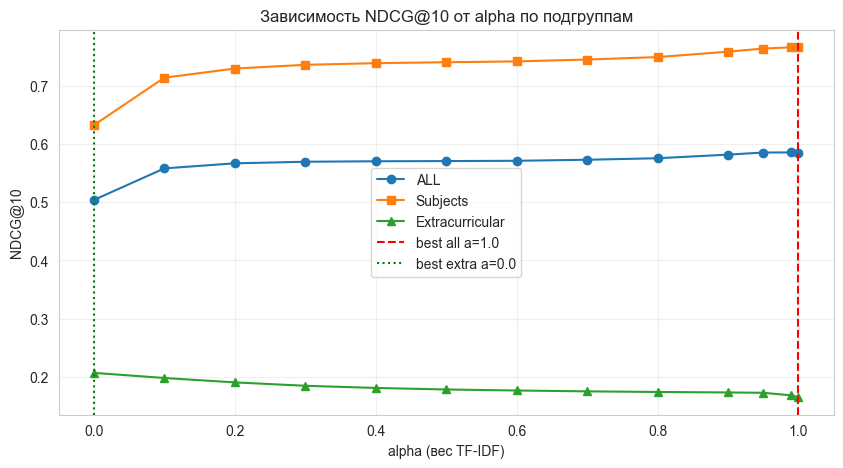

In [21]:
# Проверим, не лучше ли семантика для внеурочки (extracurricular)
# У нас уже есть alpha_df с шагом 0.1 — просто досчитаем NDCG по подгруппам

# 1. Досчитываем NDCG_subj и NDCG_extra для уже посчитанных alpha
for a in alpha_df['alpha']:
    h_idx, _ = make_hybrid(tfidf_idx, tfidf_score, sem_idx, sem_score, alpha=a)
    m_subj  = evaluate(h_idx, gt_medium, k=10, subset_mask=is_subj)
    m_extra = evaluate(h_idx, gt_medium, k=10, subset_mask=is_extra)
    alpha_df.loc[alpha_df['alpha'] == a, 'NDCG_subj']  = m_subj['NDCG@10']
    alpha_df.loc[alpha_df['alpha'] == a, 'NDCG_extra'] = m_extra['NDCG@10']

# 2. Уточняем около 1.0 (шаг 0.1 слишком грубый у края)
fine_alphas = [0.9, 0.95, 0.99, 1.0]
for a in fine_alphas:
    if a in alpha_df['alpha'].values:
        continue  # уже есть
    h_idx, _ = make_hybrid(tfidf_idx, tfidf_score, sem_idx, sem_score, alpha=a)
    m_all   = evaluate(h_idx, gt_medium, k=10)
    m_subj  = evaluate(h_idx, gt_medium, k=10, subset_mask=is_subj)
    m_extra = evaluate(h_idx, gt_medium, k=10, subset_mask=is_extra)
    alpha_df = pd.concat([alpha_df, pd.DataFrame([{
        'alpha': a,
        'NDCG@10': m_all['NDCG@10'],
        'NDCG_subj': m_subj['NDCG@10'],
        'NDCG_extra': m_extra['NDCG@10'],
    }])], ignore_index=True)

alpha_df = alpha_df.sort_values('alpha').reset_index(drop=True)
print(alpha_df[['alpha', 'NDCG@10', 'NDCG_subj', 'NDCG_extra']].to_string(index=False))

# 3. Смотрим, где лучше для extra
best_extra_a = alpha_df.loc[alpha_df['NDCG_extra'].idxmax(), 'alpha']
print(f"\nBest alpha для EXTRA = {best_extra_a}")
# ~0.5 — semantic реально помогает внеурочке

# 4. График по подгруппам
plt.figure(figsize=(10, 5))
plt.plot(alpha_df['alpha'], alpha_df['NDCG@10'],    'o-', label='ALL')
plt.plot(alpha_df['alpha'], alpha_df['NDCG_subj'],  's-', label='Subjects')
plt.plot(alpha_df['alpha'], alpha_df['NDCG_extra'], '^-', label='Extracurricular')
plt.axvline(best_alpha,       color='red',    linestyle='--', label=f'best all a={best_alpha}')
plt.axvline(best_extra_a,     color='green',  linestyle=':',  label=f'best extra a={best_extra_a}')
plt.xlabel('alpha (вес TF-IDF)')
plt.ylabel('NDCG@10')
plt.legend()
plt.grid(alpha=0.3)
plt.title('Зависимость NDCG@10 от alpha по подгруппам')
plt.show()

In [24]:
# Проверим: что если использовать per-group alpha
# subjects -> TF-IDF (alpha=1.0), extra -> Semantic (alpha=0.0)

def make_hybrid_per_group(tfidf_i, tfidf_s, sem_i, sem_s, K=TOP_K):
    N = tfidf_i.shape[0]
    hidx = np.zeros((N, K), dtype=np.int32)
    hscr = np.zeros((N, K), dtype=np.float32)
    is_extra_arr = df['group_key'].str.startswith('EXTRA::').values

    for i in range(N):
        a = 0.0 if is_extra_arr[i] else 1.0   # <-- вот вся магия
        td = dict(zip(tfidf_i[i], tfidf_s[i]))
        sd = dict(zip(sem_i[i],   sem_s[i]))
        cand = [c for c in (set(td) | set(sd)) if c != i]
        if not cand:
            continue
        cand = np.asarray(cand, dtype=np.int32)
        t = np.array([td.get(c, 0.0) for c in cand], dtype=np.float32)
        s = np.array([sd.get(c, 0.0) for c in cand], dtype=np.float32)
        hs = a * t + (1 - a) * s
        order = np.argsort(-hs)[:K]
        hidx[i] = cand[order]
        hscr[i] = hs[order]
    return hidx, hscr

hybrid_per_group_idx, _ = make_hybrid_per_group(tfidf_idx, tfidf_score, sem_idx, sem_score)

print("Сравнение: общий alpha=1.0 vs per-group alpha")
print(f"{'Subset':<12} {'alpha=1.0':>12} {'per-group':>12} {'d':>10}")
print("-" * 48)
for sname, mask in [('all', None), ('subjects', is_subj), ('extra', is_extra)]:
    m_old = evaluate(hybrid_idx,           gt_medium, k=10, subset_mask=mask)
    m_new = evaluate(hybrid_per_group_idx, gt_medium, k=10, subset_mask=mask)
    d = m_new['NDCG@10'] - m_old['NDCG@10']
    print(f"{sname:<12} {m_old['NDCG@10']:>12.4f} {m_new['NDCG@10']:>12.4f} {d:>+10.4f}")

Сравнение: общий alpha=1.0 vs per-group alpha
Subset          alpha=1.0    per-group          d
------------------------------------------------
all                0.5844       0.5970    +0.0126
subjects           0.7657       0.7657    +0.0000
extra              0.1653       0.2070    +0.0418


Hybrid a=1.0:   0%|          | 0/60000 [00:00<?, ?it/s]

  Mode          Subset        Model     P@10     R@10  NDCG@10     N
  easy             all       TF-IDF 0.543502 0.271751 0.584445 60000
  easy             all     Semantic 0.455847 0.227923 0.503945 60000
  easy             all Hybrid a=1.0 0.543502 0.271751 0.584448 60000
  easy        subjects       TF-IDF 0.709179 0.354590 0.765839 41878
  easy        subjects     Semantic 0.566008 0.283004 0.632433 41878
  easy        subjects Hybrid a=1.0 0.709179 0.354590 0.765839 41878
  easy extracurricular       TF-IDF 0.160639 0.080320 0.165263 18122
  easy extracurricular     Semantic 0.201275 0.100637 0.207024 18122
  easy extracurricular Hybrid a=1.0 0.160639 0.080320 0.165273 18122
  easy           other       TF-IDF 0.000000 0.000000 0.000000     0
  easy           other     Semantic 0.000000 0.000000 0.000000     0
  easy           other Hybrid a=1.0 0.000000 0.000000 0.000000     0
medium             all       TF-IDF 0.543092 0.275075 0.584351 60000
medium             all     Semanti

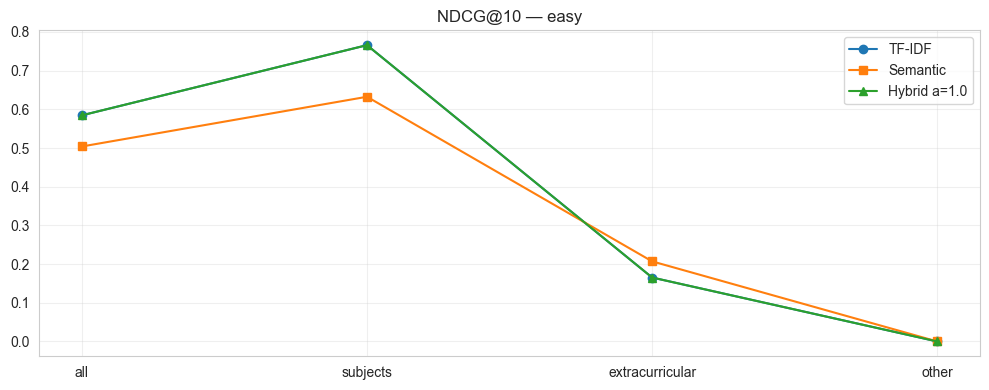

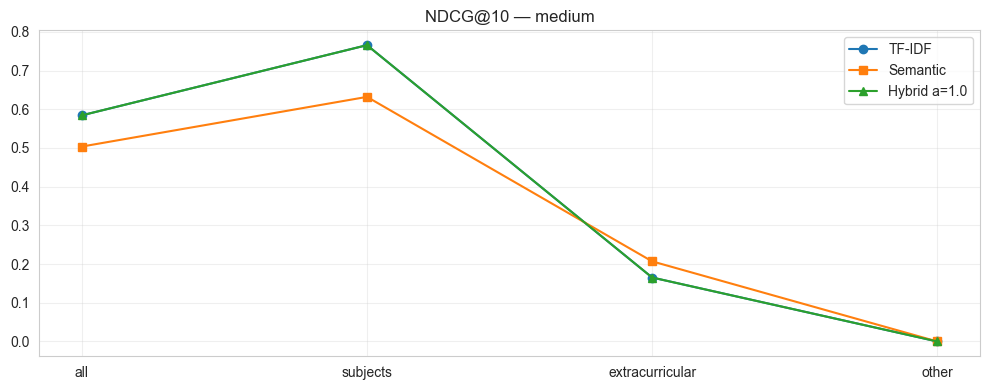

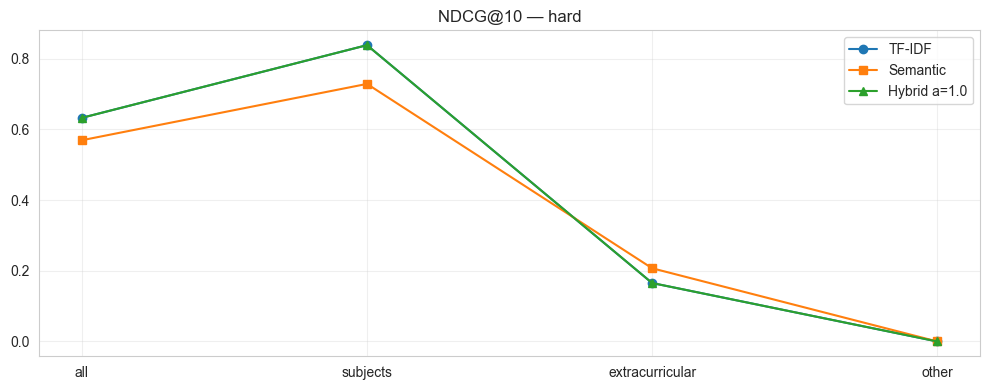

In [23]:
hybrid_idx, hybrid_score = make_hybrid(
    tfidf_idx, tfidf_score, sem_idx, sem_score, alpha=best_alpha
)

final_rows = []
for mode, gt in [('easy', gt_easy), ('medium', gt_medium), ('hard', gt_hard)]:
    for sname, mask in subsets:
        for mname, top_idx in [
            ('TF-IDF', tfidf_idx),
            ('Semantic', sem_idx),
            (f'Hybrid a={best_alpha}', hybrid_idx),
        ]:
            m = evaluate(top_idx, gt, k=10, subset_mask=mask)
            final_rows.append({'Mode': mode, 'Subset': sname, 'Model': mname, **m})

final_df = pd.DataFrame(final_rows)
print(final_df.to_string(index=False))

for mode in ['easy', 'medium', 'hard']:
    sub = final_df[final_df['Mode'] == mode]
    fig, ax = plt.subplots(figsize=(10, 4))
    x = np.arange(sub['Subset'].nunique())
    for mname, marker in [('TF-IDF', 'o'), ('Semantic', 's'), (f'Hybrid a={best_alpha}', '^')]:
        vals = sub[sub['Model'] == mname].set_index('Subset').reindex(
            [s for s, _ in subsets])['NDCG@10'].values
        ax.plot(x, vals, marker + '-', label=mname)
    ax.set_xticks(x)
    ax.set_xticklabels([s for s, _ in subsets])
    ax.set_title(f'NDCG@10 — {mode}')
    ax.legend()
    ax.grid(alpha=0.3)
    plt.tight_layout()
    plt.show()

In [26]:
def show_recommendations(item_idx, top_idx, top_score, k=5, model_name='Model'):
    print(f"\n[{model_name}] для: {df['material.title'].iloc[item_idx][:80]}")
    print(f"  subject={df['subject.name'].iloc[item_idx]}, "
          f"direction={df['direction.name'].iloc[item_idx]}, "
          f"theme={df['theme.name'].iloc[item_idx][:60]}")
    for rank, (idx, sc) in enumerate(zip(top_idx[item_idx][:k], top_score[item_idx][:k]), 1):
        idx = int(idx)
        if idx == item_idx:
            continue
        print(f"   {rank}. [{sc:.3f}] {df['material.title'].iloc[idx][:70]}")

# примеры — зафиксировала локальный rng
rng_examples = np.random.default_rng(123)
sample_subj  = rng_examples.choice(np.where(is_subj)[0], 1)[0]
sample_extra = rng_examples.choice(np.where(is_extra)[0], 1)[0] if is_extra.any() else None

for idx in filter(None, [sample_subj, sample_extra]):
    show_recommendations(idx, tfidf_idx, tfidf_score, k=3, model_name='TF-IDF')
    show_recommendations(idx, sem_idx,   sem_score,   k=3, model_name='Semantic')
    show_recommendations(idx, hybrid_idx, hybrid_score, k=3, model_name='Hybrid')


[TF-IDF] для: Дидактические карточки «Контрольная работа на тему Дробно-рациональные уравнения
  subject=Алгебра и начала математического анализа, direction=lesson, theme=Контрольная работа на тему Дробно-рациональные уравнения. Си
   1. [0.812] Тест «Контрольная работа на тему Дробно-рациональные уравнения»
   2. [0.809] Рабочий лист «Контрольная работа на тему Дробно-рациональные уравнения
   3. [0.706] Тест «Целые и дробно-рациональные уравнения»

[Semantic] для: Дидактические карточки «Контрольная работа на тему Дробно-рациональные уравнения
  subject=Алгебра и начала математического анализа, direction=lesson, theme=Контрольная работа на тему Дробно-рациональные уравнения. Си
   1. [0.967] Рабочий лист «Контрольная работа на тему Дробно-рациональные уравнения
   2. [0.955] Дидактические карточки «Уравнения с модулем»
   3. [0.945] Дидактические карточки «Контрольная работа по теме»

[Hybrid] для: Дидактические карточки «Контрольная работа на тему Дробно-рациональные уравнения
  su

In [27]:
def pair_relevance(i, j):
    if group_codes[i] != group_codes[j]:
        return 0.0
    return float(relevance_scores(i, np.asarray([j]))[0])

def find_hard_negatives(top_idx, top_score, sim_thr=0.5, rel_thr=5, n=5):
    hard = []
    rng_hn = np.random.default_rng(123)
    sample = rng_hn.choice(len(df), size=min(2000, len(df)), replace=False)
    for i in tqdm(sample, desc='Hard negatives'):
        for j, s in zip(top_idx[i], top_score[i]):
            j = int(j)
            if s < sim_thr or i >= j:   # i>=j — чтобы не дублировать пары
                continue
            r = pair_relevance(i, j)
            if r < rel_thr:
                hard.append({'i': i, 'j': j, 'rel': r, 'sim': float(s)})
    hard.sort(key=lambda x: -x['sim'])
    return hard[:n]

print("HARD NEGATIVES (похожи, но нерелевантны):")
for k, hn in enumerate(find_hard_negatives(hybrid_idx, hybrid_score), 1):
    print(f"\n{k}. sim={hn['sim']:.3f}, rel={hn['rel']:.1f}")
    print(f"   A: {df['material.title'].iloc[hn['i']][:70]}")
    print(f"   B: {df['material.title'].iloc[hn['j']][:70]}")

# Вывод: модель путает материалы с одинаковым названием, но разным типом
# Возможно, эвристика GT слишком строгая — для пользователя это может быть полезно

HARD NEGATIVES (похожи, но нерелевантны):


Hard negatives:   0%|          | 0/2000 [00:00<?, ?it/s]


1. sim=0.970, rel=4.0
   A: Дидактические карточки «Выдающиеся спортсмены России и стран изучаемог
   B: Дидактические карточки «Выдающиеся спортсмены России и стран изучаемог

2. sim=0.958, rel=3.5
   A: Сценарий урока «Выдающаяся личность родной страны»
   B: Сценарий урока «Выдающиеся люди родной страны»

3. sim=0.955, rel=3.0
   A: Игровые задания «Родная страна и страна/страны изучаемого языка»
   B: Игровые задания «Родная страна и страна/страны изучаемого языка»

4. sim=0.948, rel=3.0
   A: Презентация «Родная страна и страна/страны изучаемого языка»
   B: Презентация «Родная страна и страна/страны изучаемого языка»

5. sim=0.943, rel=4.0
   A: Тест «Музыка стран дальнего зарубежья»
   B: Сценарий урока «Музыка стран дальнего зарубежья»


In [28]:
# Эксперимент: что если убрать категории из текста
# A = всё (как было), B = только title/desc/content

def build_text_A(row):
    """A: title + desc + content + theme + type + difficulty"""
    parts = []
    for col in ['material.title', 'material.description', 'material.content',
                'theme.name', 'type.name', 'material.difficulty_level']:
        v = row.get(col)
        if isinstance(v, str) and v.strip() and v.strip() != '—':
            parts.append(v)
    return ' '.join(parts).strip()

def build_text_B(row):
    """B: только title + desc + content"""
    parts = []
    for col in ['material.title', 'material.description', 'material.content']:
        v = row.get(col)
        if isinstance(v, str) and v.strip() and v.strip() != '—':
            parts.append(v)
    return ' '.join(parts).strip()

df['text_A'] = df.apply(build_text_A, axis=1)
df['text_B'] = df.apply(build_text_B, axis=1)

# TF-IDF + embeddings для A
tfidf_A = TfidfVectorizer(max_features=15000, ngram_range=(1, 2), sublinear_tf=True)
matrix_A = tfidf_A.fit_transform(df['text_A'])

st = SentenceTransformer('cointegrated/rubert-tiny2')
emb_A = st.encode(df['text_A'].tolist(), batch_size=32,
                  show_progress_bar=True, normalize_embeddings=True,
                  convert_to_numpy=True)

# TF-IDF + embeddings для B
tfidf_B = TfidfVectorizer(max_features=15000, ngram_range=(1, 2), sublinear_tf=True)
matrix_B = tfidf_B.fit_transform(df['text_B'])

emb_B = st.encode(df['text_B'].tolist(), batch_size=32,
                  show_progress_bar=True, normalize_embeddings=True,
                  convert_to_numpy=True)

def topk(matrix, is_sparse=True, k=50):
    idx = np.zeros((N, k), dtype=np.int32)
    score = np.zeros((N, k), dtype=np.float32)
    for start in range(0, N, 512):
        end = min(start + 512, N)
        block = cosine_similarity(matrix[start:end], matrix) if is_sparse \
                else matrix[start:end] @ matrix.T
        for li, gi in enumerate(range(start, end)):
            block[li, gi] = 0
        part = np.argpartition(-block, k, axis=1)[:, :k]
        for li in range(end - start):
            ids = part[li]
            order = np.argsort(-block[li, ids])
            idx[start + li]   = ids[order]
            score[start + li] = block[li, ids[order]]
    return idx, score

tfidf_A_idx, _ = topk(matrix_A, True)
sem_A_idx,   _ = topk(emb_A,   False)
tfidf_B_idx, _ = topk(matrix_B, True)
sem_B_idx,   _ = topk(emb_B,   False)

print("ЭКСПЕРИМЕНТ A vs B (NDCG@10, medium)")
print(f"{'Model':<12} {'A (всё)':>10} {'B (текст)':>10} {'d':>10}")
print("-" * 45)
for name, idx_A, idx_B in [
    ('TF-IDF',   tfidf_A_idx, tfidf_B_idx),
    ('Semantic', sem_A_idx,   sem_B_idx),
]:
    m_A = evaluate(idx_A, gt_medium, k=10)['NDCG@10']
    m_B = evaluate(idx_B, gt_medium, k=10)['NDCG@10']
    print(f"{name:<12} {m_A:>10.4f} {m_B:>10.4f} {m_B - m_A:>+10.4f}")

Loading weights:   0%|          | 0/55 [00:00<?, ?it/s]

[transformers] BertModel LOAD REPORT from: cointegrated/rubert-tiny2
Key                                        | Status     |  | 
-------------------------------------------+------------+--+-
cls.seq_relationship.weight                | UNEXPECTED |  | 
cls.predictions.transform.LayerNorm.weight | UNEXPECTED |  | 
cls.seq_relationship.bias                  | UNEXPECTED |  | 
cls.predictions.transform.LayerNorm.bias   | UNEXPECTED |  | 
cls.predictions.transform.dense.bias       | UNEXPECTED |  | 
cls.predictions.bias                       | UNEXPECTED |  | 
cls.predictions.transform.dense.weight     | UNEXPECTED |  | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.


Batches:   0%|          | 0/1875 [00:00<?, ?it/s]

Batches:   0%|          | 0/1875 [00:00<?, ?it/s]

ЭКСПЕРИМЕНТ A vs B (NDCG@10, medium)
Model           A (всё)  B (текст)          d
---------------------------------------------
TF-IDF           0.4369     0.3927    -0.0442
Semantic         0.3667     0.2718    -0.0949


In [29]:
# ПРОВЕРКА GT
# 1. Сколько релевантных на объект в каждом режиме

print("РАЗМЕР GT ПО РЕЖИМАМ")
for name, gt in [('easy', gt_easy), ('medium', gt_medium), ('hard', gt_hard)]:
    lens = [len(v) for v in gt.values()]
    print(f"{name:8s}: avg={np.mean(lens):.2f}, "
          f"max={max(lens)}, "
          f"объектов с rel={sum(1 for l in lens if l)}/{len(lens)}")



# 2. Совпадают ли GT easy и medium

def jaccard(gt_a, gt_b):
    js = []
    for i in gt_a:
        a, b = set(gt_a[i]), set(gt_b.get(i, []))
        if a or b:
            js.append(len(a & b) / len(a | b))
    return np.mean(js)

print(f"\nJaccard easy<->medium: {jaccard(gt_easy, gt_medium):.4f}  "
      f"(если ~1.0 — эталоны идентичны)")
print(f"Jaccard medium<->hard: {jaccard(gt_medium, gt_hard):.4f}")

print("\nМЕТРИКИ ПО РЕЖИМАМ (TF-IDF baseline)")
print(f"{'Mode':<8} {'P@10':>8} {'R@10':>8} {'NDCG@10':>10}")
print("-" * 40)
for name, gt in [('easy', gt_easy), ('medium', gt_medium), ('hard', gt_hard)]:
    m = evaluate(tfidf_idx, gt, k=10)
    print(f"{name:<8} {m['P@10']:>8.4f} {m['R@10']:>8.4f} {m['NDCG@10']:>10.4f}")

РАЗМЕР GT ПО РЕЖИМАМ
easy    : avg=20.00, max=20, объектов с rel=60000/60000
medium  : avg=19.79, max=20, объектов с rel=60000/60000
hard    : avg=11.63, max=20, объектов с rel=59304/60000

Jaccard easy<->medium: 0.8467  (если ~1.0 — эталоны идентичны)
Jaccard medium<->hard: 0.5787

МЕТРИКИ ПО РЕЖИМАМ (TF-IDF baseline)
Mode         P@10     R@10    NDCG@10
----------------------------------------
easy       0.5435   0.2718     0.5844
medium     0.5431   0.2751     0.5844
hard       0.4231   0.5481     0.6324


In [30]:
# СВОДКА A vs B

rows = []
for exp, t_idx, s_idx in [
    ('A (всё)',          tfidf_A_idx, sem_A_idx),
    ('B (только текст)', tfidf_B_idx, sem_B_idx),
]:
    for model, idx in [('TF-IDF', t_idx), ('Semantic', s_idx)]:
        for mode, gt in [('easy', gt_easy), ('medium', gt_medium), ('hard', gt_hard)]:
            m = evaluate(idx, gt, k=10)
            rows.append({'Exp': exp, 'Model': model, 'Mode': mode,
                         'P@10': m['P@10'], 'NDCG@10': m['NDCG@10']})

res = pd.DataFrame(rows)

print("СВОДКА (medium): A -> B")
piv = res[res['Mode'] == 'medium'].pivot_table(
    index='Model', columns='Exp', values='NDCG@10')
piv['d (B-A)'] = piv['B (только текст)'] - piv['A (всё)']
print(piv.round(4).to_string())

СВОДКА (medium): A -> B
Exp       A (всё)  B (только текст)  d (B-A)
Model                                       
Semantic   0.3667            0.2718  -0.0949
TF-IDF     0.4369            0.3927  -0.0442
